# Lab 6
### Exploration of Mesa Framework for Agent-Based Modeling

By: Alex Horyshevskyi

### Installing dependencies

In [75]:
%pip install -U "mesa[rec]" matplotlib networkx --quiet

Note: you may need to restart the kernel to use updated packages.


### Importing Mesa components

In [76]:
from mesa import Agent, Model
from mesa.space import MultiGrid
from mesa.datacollection import DataCollector

import matplotlib.pyplot as plt

### Creating an agent

In [77]:
class SimpleAgent(Agent):
    def __init__(self, model):
        super().__init__(model)

    def step(self):
        # Простий агент без поведінки - використовується для базової демонстрації
        pass

### Creating a model

In [78]:
class SimpleModel(Model):
    def __init__(self, num_agents, width, height):
        # Ensure Model is properly initialized
        super().__init__()

        # Model parameters
        self.num_agents = num_agents
        self.grid = MultiGrid(width, height, True)

        # Create agents
        for _ in range(self.num_agents):
            a = SimpleAgent(self)
            self.agents.add(a)
            x = self.random.randrange(self.grid.width)
            y = self.random.randrange(self.grid.height)
            self.grid.place_agent(a, (x, y))

        # Collect data
        self.datacollector = DataCollector(
            agent_reporters={
                "Position": lambda a: (a.pos if hasattr(a, "pos") else None)
            }
        )

    def step(self):
        self.datacollector.collect(self)
        self.agents.shuffle_do("step")

### Running the agent

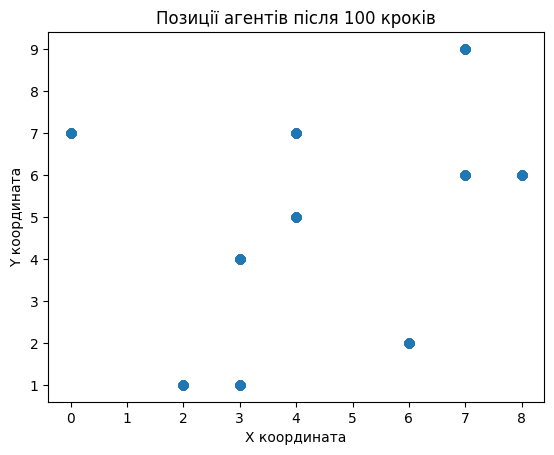

In [79]:
model = SimpleModel(10, 10, 10)
for i in range(100):
    model.step()

data = model.datacollector.get_agent_vars_dataframe()
x, y = zip(*data["Position"].values)

plt.scatter(x, y)
plt.xlabel("X координата")
plt.ylabel("Y координата")
plt.title("Позиції агентів після 100 кроків")
plt.show()

## Demographic Prisoner’s Dilemma on a Grid
https://mesa.readthedocs.io/stable/examples/advanced/pd_grid.html

### Creating Prisoner's Dilemma Agent

Agent inherits `CellAgent`, which enables it to be a part of the grid. 

#### Properties of the agent:
- `move`: current strategy ("C" або "D")
- `next_move`: next turn strategy
- `score`: total score of interactions with neighbors
- `cell`: current position of an agent

#### Agent behavior
1. In `step()` method the agent finds a top-scoring neighbor
2. Copies its strategy into the `next_move`
3. In `advance()` method applies the new strategy and updates the score
4. The score is re-calculated based on payoff matrix with all the neighbors

In [80]:
from mesa.discrete_space import CellAgent


class PDAgent(CellAgent):
    """Agent member of the iterated, spatial prisoner's dilemma model."""

    def __init__(self, model, starting_move=None, cell=None):
        """
        Create a new Prisoner's Dilemma agent.

        Args:
            model: model instance
            starting_move: If provided, determines the agent's initial state:
                           C(ooperating) or D(efecting). Otherwise, random.
        """
        super().__init__(model)
        self.score = 0
        self.cell = cell
        if starting_move:
            self.move = starting_move
        else:
            self.move = self.random.choice(["C", "D"])
        self.next_move = None

    def step(self):
        """Get the best neighbor's move, and change own move accordingly
        if better than own score."""
        if self.cell is None:
            return
        
        neighbors = [*list(self.cell.neighborhood.agents), self]
        best_neighbor = max(neighbors, key=lambda a: a.score)
        self.next_move = best_neighbor.move

        if self.model.activation_order != "Simultaneous": # type: ignore (PDAgent)
            self.advance()

    def advance(self):
        self.move = self.next_move
        self.score += self.increment_score()

    def increment_score(self):
        if self.cell is None:
            return 0
        
        neighbors = self.cell.neighborhood.agents
        if self.model.activation_order == "Simultaneous": # type: ignore (PDAgent)
            moves = [neighbor.next_move for neighbor in neighbors] # type: ignore (PDAgent)
        else:
            moves = [neighbor.move for neighbor in neighbors] # type: ignore (PDAgent)
        return sum(self.model.payoff[(self.move, move)] for move in moves) # type: ignore (PDAgent)


### Model creation (PdGrid)

In [81]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid


class PdGrid(mesa.Model):
    """Model class for iterated, spatial prisoner's dilemma model."""

    activation_regimes = ["Sequential", "Random", "Simultaneous"]

    # This dictionary holds the payoff for this agent,
    # keyed on: (my_move, other_move)
    payoff = {("C", "C"): 1.5, ("C", "D"): -0.5, ("D", "C"): 2, ("D", "D"): 0.3}

    def __init__(
        self, width=50, height=50, activation_order="Random", payoffs=None, seed=None
    ):
        """
        Create a new Spatial Prisoners' Dilemma Model.

        Args:
            width, height: Grid size. There will be one agent per grid cell.
            activation_order: Can be "Sequential", "Random", or "Simultaneous".
                           Determines the agent activation regime.
            payoffs: (optional) Dictionary of (move, neighbor_move) payoffs.
        """
        super().__init__(seed=seed)
        self.activation_order = activation_order
        self.grid = OrthogonalMooreGrid((width, height), torus=True, random=self.random)

        if payoffs is not None:
            self.payoff = payoffs

        PDAgent.create_agents(
            self, len(self.grid.all_cells.cells), cell=self.grid.all_cells.cells
        )

        self.datacollector = mesa.DataCollector(
            {
                "Cooperating_Agents": lambda m: len(
                    [a for a in m.agents if hasattr(a, 'move') and a.move == "C"]
                )
            }
        )

        self.running = True
        self.datacollector.collect(self)

    def step(self):
        # Activate all agents, based on the activation regime
        match self.activation_order:
            case "Sequential":
                self.agents.do("step")
            case "Random":
                self.agents.shuffle_do("step")
            case "Simultaneous":
                self.agents.do("step")
                self.agents.do("advance")
            case _:
                raise ValueError(f"Unknown activation order: {self.activation_order}")

        # Collect data
        self.datacollector.collect(self)

    def run(self, n):
        """Run the model for n steps."""
        for _ in range(n):
            self.step()


### Running the model

In [82]:
"""
Matplotlib-based visualization for the Spatial Prisoner's Dilemma Model.
"""
import matplotlib.pyplot as plt
import numpy as np

model = PdGrid(width=100, height=100, seed=42)
steps = 100

initial_state = np.zeros((model.grid.height, model.grid.width))
for idx, cell in enumerate(model.grid.all_cells.cells):  # type: ignore
    pos = (idx % model.grid.width, idx // model.grid.width)
    if cell.agents:  # type: ignore
        agent = list(cell.agents)[0]  # type: ignore
        if hasattr(agent, 'move'):  # type: ignore
            initial_state[pos[1]][pos[0]] = 1 if agent.move == "C" else 0  # type: ignore

cooperation_counts = []
all_scores = []

initial_cooperating = len([
    a for a in model.agents if hasattr(a, 'move') 
    and a.move == "C" # type: ignore (PDAgent child has move attribute)
])
cooperation_counts.append(initial_cooperating)

for step in range(steps):
    model.step()
    cooperating_agents = len([
        a for a in model.agents 
        if hasattr(a, 'move') and a.move == "C" # type: ignore (PDAgent child has move attribute)
    ])
    cooperation_counts.append(cooperating_agents)
    
    if step % 10 == 0:
        scores = [a.score for a in model.agents] # type: ignore (PDAgent has score attribute)
        all_scores.append(scores)

# Stats

final_scores = [a.score for a in model.agents if hasattr(a, 'score')] # type: ignore (PDAgent has score attribute)

print(f"""Modelling statistics:
Total agents: {len(model.agents)}
Initial cooperating agents: {cooperation_counts[0]}
Final cooperating agents: {cooperation_counts[-1]}
Change: {cooperation_counts[-1] - cooperation_counts[0]} agents
Average score: {np.mean(final_scores):.2f}
Max score: {np.max(final_scores):.2f}
Min score: {np.min(final_scores):.2f}""")

Modelling statistics:
Total agents: 10000
Initial cooperating agents: 4984
Final cooperating agents: 9065
Change: 4081 agents
Average score: 959.00
Max score: 1200.00
Min score: 153.80


### Visualization

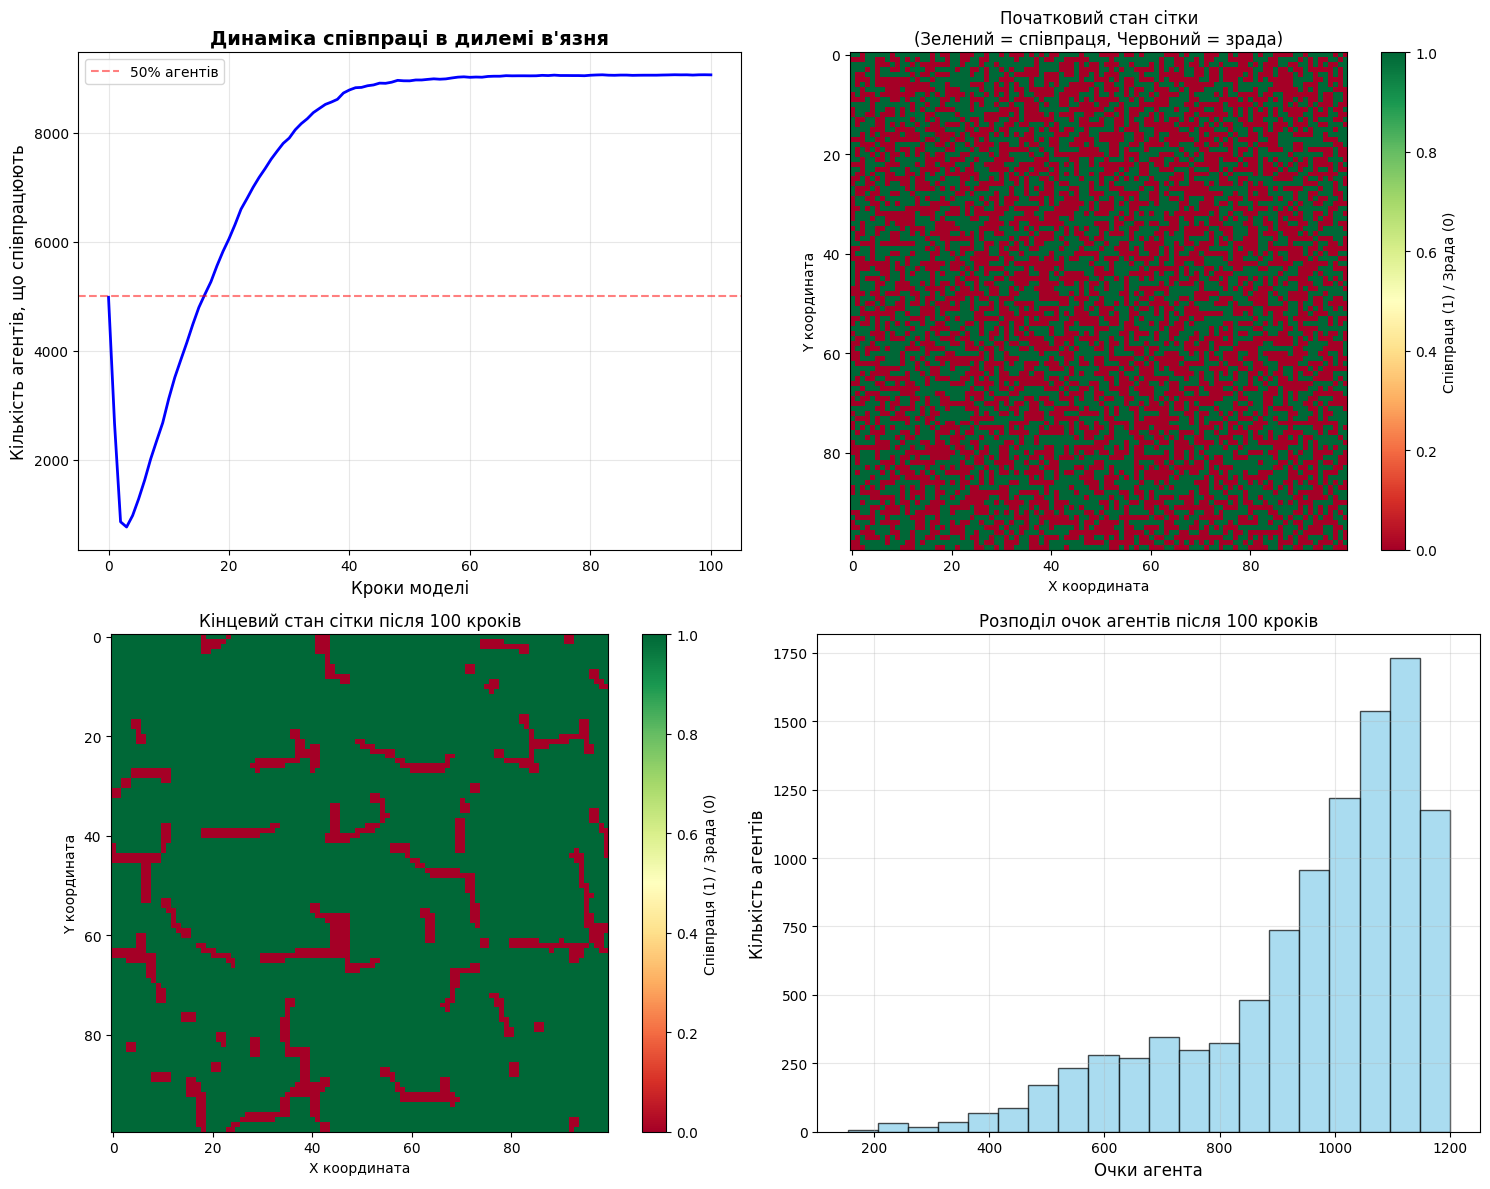

In [83]:
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# Cooperation dynamic plot
axes[0, 0].plot(range(steps + 1), cooperation_counts, linewidth=2, color='blue')
axes[0, 0].set_xlabel("Кроки моделі", fontsize=12)
axes[0, 0].set_ylabel("Кількість агентів, що співпрацюють", fontsize=12)
axes[0, 0].set_title("Динаміка співпраці в дилемі в'язня", fontsize=14, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].axhline(y=len(model.agents)/2, color='red', linestyle='--', alpha=0.5, label='50% агентів')
axes[0, 0].legend()

# Final grid status
final_state = np.zeros((model.grid.height, model.grid.width))
for idx, cell in enumerate(model.grid.all_cells.cells):  # type: ignore
    if not cell.agents:  # type: ignore
        continue
    pos = (idx % model.grid.width, idx // model.grid.width)
    agent = list(cell.agents)[0]  # type: ignore
    final_state[pos[1]][pos[0]] = 1 if agent.move == "C" else 0  # type: ignore

# Initial state
im1 = axes[0, 1].imshow(initial_state, cmap='RdYlGn', vmin=0, vmax=1)
axes[0, 1].set_title("Початковий стан сітки\n(Зелений = співпраця, Червоний = зрада)", fontsize=12)
axes[0, 1].set_xlabel("X координата")
axes[0, 1].set_ylabel("Y координата")
plt.colorbar(im1, ax=axes[0, 1], label='Співпраця (1) / Зрада (0)')

# Final state
im2 = axes[1, 0].imshow(final_state, cmap='RdYlGn', vmin=0, vmax=1)
axes[1, 0].set_title("Кінцевий стан сітки після 100 кроків", fontsize=12)
axes[1, 0].set_xlabel("X координата")
axes[1, 0].set_ylabel("Y координата")
plt.colorbar(im2, ax=axes[1, 0], label='Співпраця (1) / Зрада (0)')

# Score distribution
axes[1, 1].hist(final_scores, bins=20, color='skyblue', edgecolor='black', alpha=0.7)
axes[1, 1].set_xlabel("Очки агента", fontsize=12)
axes[1, 1].set_ylabel("Кількість агентів", fontsize=12)
axes[1, 1].set_title("Розподіл очок агентів після 100 кроків", fontsize=12)
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusions

### Analysis of simulation results

After running the model, the following phenomena can be observed:

1. **Cooperation dynamics**: The number of cooperating agents changes depending on the initial distribution and interactions. Agents copy the strategy of the most successful neighbors, which leads to the formation of clusters of cooperating or treacherous agents.

2. **Spatial structure**: Domains (clusters) of agents with the same strategy appear on the grid. This demonstrates the importance of spatial structure in the evolution of cooperation.

3. **Point distribution**: Agents in clusters of cooperating agents receive more points, since they interact mainly with other cooperating agents.

### Changes

- Fixed bugs in the code (typos, imports)
- Improved visualization (added heatmap of the grid state, histogram of points)
- Changed the grid size from 20x20 to 100x100 for a better demonstration of dynamics
- Changed metaparameters (payoffs, number of steps)

### Impact on behavior

- Fixed bugs allowed the model to work correctly
- Improved visualization allows for better observation of dynamics and cluster formation
- A smaller grid size does not change the overall behavior, but makes the results more visual
- A larger grid size allows for better study of spatial effects
- Detailed explanations make the model more understandable for training